# HW02 – Word embedding: cài đặt Word2Vec từ đầu và chạy bằng GPU, tìm 10 cặp từ tương đồng và giảm chiều

## Tóm tắt
- **Bài 1 (mục 2–6):** tự cài đặt mô hình **Word2Vec – kiến trúc Skip-gram, hàm mất mát Negative Sampling (SGNS)**, không `gensim`. Tự viết tay từ đầu: xây từ vựng, lấy mẫu con (subsampling), sinh cặp (từ trung tâm, từ ngữ cảnh), lấy mẫu âm, hàm mất mát, **đạo hàm tính bằng tay** và cập nhật bằng SGD.
- **Bài 2 (mục 7):** trên vector vừa huấn luyện, tìm 10 cặp từ tương đồng bằng cosine, rồi giảm chiều bằng **PCA tự viết** xuống 2 và 3 chiều để biểu diễn.

## 1. Cơ sở lý thuyết

### 1.1 Skip-gram
Với một câu $w_1, \dots, w_T$, Skip-gram dùng từ trung tâm $c$ để dự đoán các từ ngữ cảnh $o$ nằm trong cửa sổ $\pm m$ quanh nó.
Mỗi từ có hai vector: $v_w$ (khi làm từ trung tâm, hàng của `W_in`) và $u_w$ (khi làm từ ngữ cảnh, hàng của `W_out`).
Điểm khớp của một cặp: $s(c,o) = u_o \cdot v_c$.

### 1.2 Negative Sampling
Softmax trên toàn bộ từ vựng quá tốn kém. Thay vào đó biến bài toán thành phân loại nhị phân: cặp thật $(c,o)$ có nhãn 1; lấy thêm $K$ từ ngẫu nhiên $n_1,\dots,n_K \sim P_n$ tạo cặp giả $(c,n_k)$ có nhãn 0. Hàm mất mát của một cặp:

$$L = -\log\sigma(u_o\cdot v_c) \;-\; \sum_{k=1}^{K}\log\sigma(-u_{n_k}\cdot v_c),\qquad \sigma(x)=\frac{1}{1+e^{-x}}$$

Phân phối lấy mẫu âm: $P_n(w)\propto \text{count}(w)^{0.75}$ (làm "phẳng" bớt phân phối tần suất, từ hiếm được chọn nhiều hơn một chút).

### 1.3 Đạo hàm
Đặt $s_o = u_o\cdot v_c$ và $s_k = u_{n_k}\cdot v_c$. Vì $\frac{d}{ds}\big[-\log\sigma(s)\big]=\sigma(s)-1$ và $\frac{d}{ds}\big[-\log\sigma(-s)\big]=\sigma(s)$:

$$\frac{\partial L}{\partial s_o}=\sigma(s_o)-1,\qquad \frac{\partial L}{\partial s_k}=\sigma(s_k)$$

Áp dụng quy tắc chuỗi (với $s = u\cdot v$ thì $\partial s/\partial v = u$ và $\partial s/\partial u = v$):

$$\frac{\partial L}{\partial v_c}=(\sigma(s_o)-1)\,u_o+\sum_{k}\sigma(s_k)\,u_{n_k},\qquad
\frac{\partial L}{\partial u_o}=(\sigma(s_o)-1)\,v_c,\qquad
\frac{\partial L}{\partial u_{n_k}}=\sigma(s_k)\,v_c$$

### 1.4 Lấy mẫu con từ phổ biến (subsampling)
Các từ như "mà", "thì", "là" xuất hiện rất nhiều nhưng mang ít thông tin. Mỗi lần xuất hiện của từ $w$ (tần suất tương đối $f(w)=\text{count}(w)/N$) được giữ lại với xác suất

$$P_{\text{giữ}}(w)=\min\!\Big(1,\ \big(\sqrt{f(w)/t}+1\big)\cdot\frac{t}{f(w)}\Big),\qquad t=10^{-4}$$

### 1.5 Cập nhật tham số
Dùng SGD theo minibatch: tổng đạo hàm của các cặp trong batch, rồi $\theta \leftarrow \theta - \eta\,\nabla_\theta L$, với tốc độ học $\eta$ giảm tuyến tính trong quá trình huấn luyện.

## 2. Thiết lập môi trường và GPU

Notebook dùng `torch`, `numpy`, `matplotlib` và chạy bằng kernel Colab GPU để huấn luyện.


In [16]:
import re
import time
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

torch.set_grad_enabled(False)   # đạo hàm tính tay

CORPUS_PATH = Path("corpus.txt")
OUT_DIR = Path("models")
FIG_DIR = Path("figures")

In [ ]:
assert isinstance(device, torch.device), "device phải là torch.device(...)"
if torch.cuda.is_available():
    assert device.type == "cuda", "Máy có GPU nhưng chưa chọn cuda"
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Không thấy GPU, sẽ chạy bằng CPU")

GPU: Tesla T4


So sánh tốc độ nhân ma trận 4096 × 4096 trên CPU và trên GPU T4 của Google Colab.

In [18]:
def time_matmul(dev, n=4096, repeat=5):
    a = torch.randn(n, n, device=dev)
    b = torch.randn(n, n, device=dev)
    a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(repeat):
        a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / repeat

print(f"CPU     : {time_matmul(torch.device('cpu')) * 1000:8.1f} ms")
print(f"{device.type.upper():8}: {time_matmul(device) * 1000:8.1f} ms")

CPU     :   1075.0 ms
CUDA    :     43.4 ms


## 3. Dữ liệu và tiền xử lý

### 3.1 Đọc dữ liệu và tách token
Mỗi dòng của `corpus.txt` là một câu/đoạn ngắn. Chuyển về chữ thường, bỏ dấu câu, tách mỗi tiếng một token, và bỏ các câu có dưới 2 token vì không có ngữ cảnh để học.


In [19]:
with open(CORPUS_PATH, encoding="utf-8") as f:
    lines = [ln.strip() for ln in f if ln.strip()]

def tokenize(line):
    return re.findall(r"\w+", line.lower())

sentences = [t for t in (tokenize(ln) for ln in lines) if len(t) >= 2]
print("Số câu:", len(sentences), "| Số token:", sum(len(s) for s in sentences))

Số câu: 97709 | Số token: 1953020


### 3.2 Xây dựng từ vựng
Đếm tần suất từng token, bỏ các từ xuất hiện ít hơn `MIN_COUNT` = 5 lần, các từ còn lại đánh số theo tần suất giảm dần.


In [20]:
MIN_COUNT = 5

counter = Counter(tok for s in sentences for tok in s)
kept = [(word, count) for word, count in counter.most_common() if count >= MIN_COUNT]
vocab = [word for word, _ in kept]
word2id = {word: idx for idx, word in enumerate(vocab)}
counts = torch.tensor([count for _, count in kept], dtype=torch.float32, device=device)


In [21]:
V = len(vocab)
assert V > 3000, f"Từ vựng chỉ có {V} từ"
assert all(counter[w] >= MIN_COUNT for w in vocab), "Còn từ xuất hiện ít hơn MIN_COUNT"
assert all(counter[vocab[i]] >= counter[vocab[i + 1]] for i in range(V - 1)), "vocab chưa sắp theo tần suất giảm dần"
assert all(word2id[w] == i for i, w in enumerate(vocab)), "word2id không khớp vocab"
assert counts.shape == (V,) and counts.device.type == device.type and counts.dtype == torch.float32
assert counts[word2id["ông"]].item() == counter["ông"]
print("Kích thước từ vựng V =", V)

Kích thước từ vựng V = 4310


### 3.3 Mã hóa kho ngữ liệu
Tạo cặp từ bằng thao tác vector hóa bằng cách nối tất cả các câu thành một mảng có `id` của `token` trong từ vựng, một mảng song song `sids` note lại token đó thuộc câu nào.

In [22]:
token_ids = []
sentence_ids = []
for sentence_id, sentence in enumerate(sentences):
    for token in sentence:
        token_id = word2id.get(token)
        if token_id is not None:
            token_ids.append(token_id)
            sentence_ids.append(sentence_id)

ids = torch.tensor(token_ids, dtype=torch.int64, device=device)
sids = torch.tensor(sentence_ids, dtype=torch.int64, device=device)


In [23]:
assert ids.shape == sids.shape and ids.dim() == 1
assert ids.device.type == device.type and sids.device.type == device.type, "Chưa chuyển lên device"
assert ids.dtype == torch.int64 and sids.dtype == torch.int64
assert len(ids) == int(counts.sum().item()), "Số token phải bằng tổng counts"
assert 0 <= ids.min() and ids.max() < V
assert bool((sids[1:] >= sids[:-1]).all()), "sids phải không giảm"
print("Số token dùng để huấn luyện:", len(ids))

Số token dùng để huấn luyện: 1949793


### 3.4 Xác suất giữ từ (subsampling)
(1.4): $P_{\text{giữ}}(w)=\min\big(1,\ (\sqrt{f/t}+1)\cdot t/f\big)$ với $f = \text{counts}/\text{counts.sum()}$.

In [ ]:
def keep_prob(counts, t=1e-4):
    frequency = counts / counts.sum()
    probability = (torch.sqrt(frequency / t) + 1) * (t / frequency)
    return torch.clamp(probability, max=1.0)


In [25]:
keep = keep_prob(counts)
assert keep.shape == (V,) and bool((keep > 0).all()) and bool((keep <= 1).all())
assert keep[0] < 0.2, "Từ phổ biến nhất phải bị bỏ khá nhiều"
assert keep[-1] == 1.0, "Từ hiếm nhất phải luôn được giữ"
assert bool((keep[1:] >= keep[:-1] - 1e-6).all()), "Từ càng hiếm thì xác suất giữ càng cao"
print("keep_prob đúng. Ví dụ:", {w: round(keep[word2id[w]].item(), 3) for w in ["mà", "ông", "cha", "vua"]})

keep_prob đúng. Ví dụ: {'mà': 0.075, 'ông': 0.112, 'cha': 0.221, 'vua': 1.0}


### 3.5 Sinh cặp (từ trung tâm, từ ngữ cảnh)
Với cửa sổ `window`, mỗi token ở vị trí $i$ tạo cặp với token ở vị trí $i\pm 1, \dots, i\pm \text{window}$ nếu cùng một câu.

Vector hóa: với mỗi khoảng cách `off` từ 1 đến `window`, so sánh mảng `ids` với chính nó dịch đi `off` vị trí; hai token cách nhau `off` vị trí ở cùng câu khi `sids[:-off] == sids[off:]`.

In [ ]:
def make_pairs(ids, sids, window):
    centers_parts = []
    contexts_parts = []

    for off in range(1, window + 1):
        if off >= len(ids):
            break
        mask = sids[:-off] == sids[off:]
        left = ids[:-off][mask]
        right = ids[off:][mask]
        centers_parts.extend((left, right))
        contexts_parts.extend((right, left))

    if not centers_parts:
        empty = ids.new_empty((0,))
        return empty, empty.clone()
    return torch.cat(centers_parts), torch.cat(contexts_parts)


In [ ]:
_ids = torch.tensor([1, 2, 3, 4, 5])
_sids = torch.tensor([0, 0, 0, 1, 1])

c, o = make_pairs(_ids, _sids, 1)
assert set(zip(c.tolist(), o.tolist())) == {(1, 2), (2, 1), (2, 3), (3, 2), (4, 5), (5, 4)}, "window=1 sai"
c, o = make_pairs(_ids, _sids, 2)
assert set(zip(c.tolist(), o.tolist())) == {(1, 2), (2, 1), (2, 3), (3, 2), (1, 3), (3, 1), (4, 5), (5, 4)}, "window=2 sai"
assert len(c) == len(o) == 8
print("make_pairs đúng")

make_pairs đúng


### 3.6 Phân phối lấy mẫu âm
Dùng công thức $P_n(w)\propto \text{count}(w)^{0.75}$

In [28]:
def noise_distribution(counts, power=0.75):
    weights = counts.pow(power)
    return weights / weights.sum()

In [29]:
noise = noise_distribution(counts)
assert noise.shape == (V,) and abs(noise.sum().item() - 1.0) < 1e-4
expected = (counts[0] / counts[-1]) ** 0.75
assert abs((noise[0] / noise[-1]).item() / expected.item() - 1) < 1e-3, "Chưa đúng lũy thừa 0.75"
print("noise_distribution đúng")

noise_distribution đúng


## 4. Mô hình

### 4.1 Khởi tạo tham số
Hai ma trận kích thước `V × D`:
- `W_in`: giá trị ngẫu nhiên nhỏ, đều trong khoảng $[-0.5/D,\ 0.5/D]$
- `W_out`: toàn số 0

In [30]:
D = 100

def init_params(V, D, device, seed=0):
    g = torch.Generator(device=device)
    g.manual_seed(seed)
    W_in = (torch.rand(V, D, device=device, generator=g) - 0.5) / D
    W_out = torch.zeros((V, D), dtype=W_in.dtype, device=device)
    return W_in, W_out, g


In [31]:
W_in, W_out, g = init_params(V, D, device)
assert W_in.shape == (V, D) and W_out.shape == (V, D)
assert W_in.device.type == device.type and W_out.device.type == device.type
assert W_in.abs().max().item() <= 0.5 / D + 1e-8 and W_in.abs().max().item() > 0.25 / D
assert bool((W_out == 0).all())
print("init_params đúng")

init_params đúng


### 4.2 log-sigmoid ổn định số học
`log(sigmoid(x))` bị tràn số khi $|x|$ lớn $\rightarrow$ Dùng đồng nhất thức: $\log\sigma(x) = -\text{softplus}(-x)$, $\text{softplus}(z)=\max(z,0)+\log\big(1+e^{-|z|}\big)$.

In [32]:
def log_sigmoid(x):
    """Tính log(sigmoid(x)) ổn định số học."""
    z = -x
    softplus = torch.clamp(z, min=0) + torch.log1p(torch.exp(-torch.abs(z)))
    return -softplus


In [33]:
x = torch.tensor([-1000.0, -10.0, 0.0, 10.0, 1000.0])
y = log_sigmoid(x)
assert bool(torch.isfinite(y).all()), "Có inf/nan khi |x| lớn"
assert abs(y[2].item() + np.log(2)) < 1e-6, "log σ(0) phải bằng -ln 2"
assert abs(y[0].item() + 1000.0) < 1e-3 and abs(y[4].item()) < 1e-6
assert abs(y[1].item() - float(np.log(1 / (1 + np.exp(10))))) < 1e-5
print("log_sigmoid đúng")

log_sigmoid đúng


### 4.3 Hàm mất mát và đạo hàm
Cài một batch gồm $B$ cặp, mỗi cặp có $K$ từ âm:

- input: `W_in`, `W_out`, `c` (shape `B`, id từ trung tâm), `o` (shape `B`, id từ ngữ cảnh), `n` (shape `B × K`, id từ âm)
- output: `loss` (tổng loss của batch, số thực), `grad_in` (cùng shape `W_in`), `grad_out` (cùng shape `W_out`)

In [ ]:
def loss_and_grads(W_in, W_out, c, o, n):
    v = W_in[c]                         # (B, D)
    u_o = W_out[o]                      # (B, D)
    u_n = W_out[n]                      # (B, K, D)

    pos = (v * u_o).sum(dim=1)          # (B,)
    neg = torch.einsum("bd,bkd->bk", v, u_n)  # (B, K)
    loss = -(log_sigmoid(pos).sum() + log_sigmoid(-neg).sum())

    dpos = torch.sigmoid(pos) - 1       # (B,)
    dneg = torch.sigmoid(neg)           # (B, K)
    grad_v = dpos[:, None] * u_o + (dneg[:, :, None] * u_n).sum(dim=1)
    grad_u_o = dpos[:, None] * v
    grad_u_n = dneg[:, :, None] * v[:, None, :]

    grad_in = torch.zeros_like(W_in)
    grad_out = torch.zeros_like(W_out)
    grad_in.index_add_(0, c, grad_v)
    grad_out.index_add_(0, o, grad_u_o)
    grad_out.index_add_(0, n.reshape(-1), grad_u_n.reshape(-1, W_out.shape[1]))
    return loss, grad_in, grad_out


Kiểm tra đạo hàm bằng sai phân hữu hạn: Với một tham số $\theta$, đạo hàm số là $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$.

In [35]:
gen = torch.Generator().manual_seed(1)
Vt, Dt, Bt, Kt = 7, 4, 5, 3
Wi = torch.randn(Vt, Dt, dtype=torch.float64, generator=gen)
Wo = torch.randn(Vt, Dt, dtype=torch.float64, generator=gen)
ct = torch.randint(0, Vt, (Bt,), generator=gen)
ot = torch.randint(0, Vt, (Bt,), generator=gen)
nt = torch.randint(0, Vt, (Bt, Kt), generator=gen)

loss, gi, go = loss_and_grads(Wi, Wo, ct, ot, nt)
assert gi.shape == Wi.shape and go.shape == Wo.shape, "grad phải cùng shape với tham số"

def numeric_grad(W, which, eps=1e-6):
    num = torch.zeros_like(W)
    for r in range(W.shape[0]):
        for k in range(W.shape[1]):
            W[r, k] += eps
            lp = loss_and_grads(Wi, Wo, ct, ot, nt)[0]
            W[r, k] -= 2 * eps
            lm = loss_and_grads(Wi, Wo, ct, ot, nt)[0]
            W[r, k] += eps
            num[r, k] = (lp - lm) / (2 * eps)
    return num

assert torch.allclose(gi, numeric_grad(Wi, "in"), atol=1e-5), "grad_in sai"
assert torch.allclose(go, numeric_grad(Wo, "out"), atol=1e-5), "grad_out sai"
print("Đạo hàm viết tay khớp với đạo hàm số. loss =", round(loss.item(), 4))

Đạo hàm viết tay khớp với đạo hàm số. loss = 18.1636


## 5. Huấn luyện

### 5.1 Tham số
| Tham số | Ý nghĩa | Giá trị |
|---|---|---|
| `D` | số chiều embedding | 100 |
| `WINDOW` | bán kính cửa sổ ngữ cảnh | 5 |
| `K` | số mẫu âm mỗi cặp | 5 |
| `SUBSAMPLE_T` | ngưỡng subsampling $t$ | 1e-4 |
| `EPOCHS` | số lần duyệt toàn bộ dữ liệu | 20 |
| `BATCH` | số cặp mỗi bước | 4096 |
| `LR` | tốc độ học ban đầu | 0.025 |

In [36]:
WINDOW = 5
K = 5
SUBSAMPLE_T = 1e-4
EPOCHS = 20
BATCH = 4096
LR = 0.025

keep = keep_prob(counts, SUBSAMPLE_T)

### 5.2 Vòng huấn luyện
Mỗi epoch:
1. Subsampling
2. Sinh cặp bằng `make_pairs` trên các token còn lại, rồi xáo trộn thứ tự các cặp.
3. Lấy `K` từ âm cho mỗi cặp bằng `torch.multinomial(noise, ...)`, tính `loss_and_grads`, cập nhật tham số từng batch.

In [ ]:
def train(W_in, W_out, g, epochs=EPOCHS, batch=BATCH, lr0=LR):
    history = []                                    # loss trung bình mỗi cặp
    step, total_steps = 0, None
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()

    for ep in range(epochs):
        epoch_t0 = time.time()
        mask = torch.rand(len(ids), device=device, generator=g) < keep[ids]
        centers, contexts = make_pairs(ids[mask], sids[mask], WINDOW)
        perm = torch.randperm(len(centers), device=device, generator=g)
        centers, contexts = centers[perm], contexts[perm]

        n_batches = (len(centers) + batch - 1) // batch
        if total_steps is None:
            total_steps = n_batches * epochs
        epoch_loss = torch.zeros((), device=device)

        for b in range(n_batches):
            c = centers[b * batch:(b + 1) * batch]
            o = contexts[b * batch:(b + 1) * batch]
            n = torch.multinomial(noise, len(c) * K, replacement=True, generator=g).view(len(c), K)

            lr = lr0 * max(1 - step / total_steps, 1e-4)
            loss, grad_in, grad_out = loss_and_grads(W_in, W_out, c, o, n)
            W_in -= lr * grad_in
            W_out -= lr * grad_out

            epoch_loss += loss
            step += 1

        history.append(epoch_loss.item() / len(centers))
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_seconds = time.time() - epoch_t0
        print(f"epoch {ep + 1}/{epochs} | {len(centers):>10,} cặp | loss/cặp = {history[-1]:.4f} | {epoch_seconds:6.1f}s")
    print(f"Tổng thời gian huấn luyện: {time.time() - t0:.1f}s")
    return history


### 5.3 Chạy huấn luyện

In [38]:
W_in, W_out, g = init_params(V, D, device, seed=0)
history = train(W_in, W_out, g)

epoch 1/20 |  5,786,494 cặp | loss/cặp = 2.6246 |    1.3s
epoch 2/20 |  5,795,892 cặp | loss/cặp = 2.4522 |    1.1s
epoch 3/20 |  5,801,940 cặp | loss/cặp = 2.4180 |    1.1s
epoch 4/20 |  5,798,836 cặp | loss/cặp = 2.4024 |    1.1s
epoch 5/20 |  5,799,202 cặp | loss/cặp = 2.3906 |    1.1s
epoch 6/20 |  5,786,334 cặp | loss/cặp = 2.3811 |    1.1s
epoch 7/20 |  5,791,192 cặp | loss/cặp = 2.3749 |    1.1s
epoch 8/20 |  5,798,014 cặp | loss/cặp = 2.3683 |    1.1s
epoch 9/20 |  5,799,386 cặp | loss/cặp = 2.3639 |    1.1s
epoch 10/20 |  5,790,758 cặp | loss/cặp = 2.3571 |    1.1s
epoch 11/20 |  5,792,562 cặp | loss/cặp = 2.3530 |    1.1s
epoch 12/20 |  5,794,916 cặp | loss/cặp = 2.3483 |    1.1s
epoch 13/20 |  5,791,552 cặp | loss/cặp = 2.3433 |    1.1s
epoch 14/20 |  5,795,266 cặp | loss/cặp = 2.3393 |    1.1s
epoch 15/20 |  5,797,550 cặp | loss/cặp = 2.3355 |    1.1s
epoch 16/20 |  5,792,752 cặp | loss/cặp = 2.3306 |    1.2s
epoch 17/20 |  5,789,440 cặp | loss/cặp = 2.3272 |    1.1s
epoch 

Loss giảm từ 2.6246 xuống 2.3174


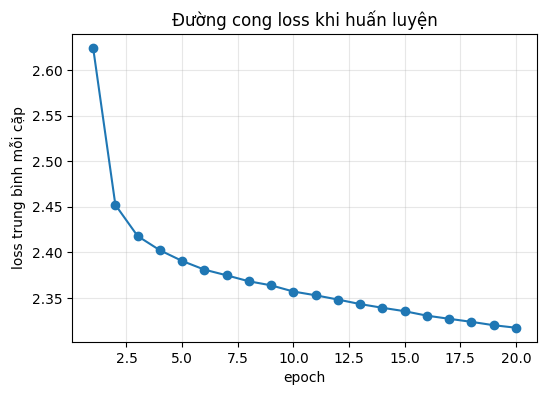

In [ ]:
assert len(history) == EPOCHS
assert history[-1] < history[0] * 0.9, "Loss không giảm"
assert bool(torch.isfinite(W_in).all()), "W_in có nan/inf"
print("Loss giảm từ", round(history[0], 4), "xuống", round(history[-1], 4))

plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), history, marker="o")
plt.xlabel("epoch")
plt.ylabel("loss trung bình mỗi cặp")
plt.title("Đường cong loss khi huấn luyện")
plt.grid(alpha=0.3)
plt.show()

## 6. Đánh giá

### 6.1 Từ gần nghĩa nhất
Hai từ gần nhau khi và chỉ chỉ khi cosine của vector chúng lớn.

In [40]:
E = W_in / W_in.norm(dim=1, keepdim=True)

def most_similar(word, k=5):
    if word not in word2id:
        raise KeyError(f"'{word}' không có trong từ vựng")
    if not 0 <= k < len(vocab):
        raise ValueError(f"k phải nằm trong [0, {len(vocab) - 1}]")

    word_id = word2id[word]
    similarities = E @ E[word_id]
    similarities[word_id] = -torch.inf
    scores, indices = similarities.topk(k)
    return [(vocab[idx], float(score)) for idx, score in zip(indices.tolist(), scores.tolist())]


In [41]:
res = most_similar("cha", 5)
assert len(res) == 5 and all(w != "cha" for w, _ in res), "Không được trả về chính từ truy vấn, và phải đủ k phần tử"
scores = [s for _, s in res]
assert scores == sorted(scores, reverse=True), "Chưa sắp giảm dần"
assert "mẹ" in [w for w, _ in most_similar("cha", 10)], "Không có 'mẹ' trong top 10 của 'cha': mô hình học chưa tốt?"
assert "bà" in [w for w, _ in most_similar("ông", 10)], "Không có 'bà' trong top 10 của 'ông'"
print("most_similar đúng\n")
for w in ["cha", "vợ", "tiền", "thương", "ông", "nhà", "khóc"]:
    print(f"{w:>8} ->", most_similar(w, 6))

most_similar đúng

     cha -> [('mẹ', 0.7824592590332031), ('con', 0.6972007751464844), ('ngoại', 0.6133443117141724), ('má', 0.6013917326927185), ('cháu', 0.5781828761100769), ('nó', 0.5658426880836487)]
      vợ -> [('chồng', 0.9181410074234009), ('cưới', 0.7069686651229858), ('con', 0.6342845559120178), ('mẹ', 0.5462831854820251), ('với', 0.5455076694488525), ('madame', 0.5373419523239136)]
    tiền -> [('bạc', 0.7993851900100708), ('xài', 0.6808002591133118), ('160', 0.6616303324699402), ('số', 0.6237885355949402), ('nhiều', 0.6225594878196716), ('trả', 0.6073902249336243)]
  thương -> [('yêu', 0.683556854724884), ('mến', 0.6117510795593262), ('vì', 0.6110407114028931), ('phàng', 0.5998222827911377), ('con', 0.5925547480583191), ('nếu', 0.5902449488639832)]
     ông -> [('bà', 0.6260212063789368), ('đó', 0.5866094827651978), ('lại', 0.5801809430122375), ('ổng', 0.5786899328231812), ('cháu', 0.5532287359237671), ('nhà', 0.5490260720252991)]
     nhà -> [('ở', 0.7371963858604431), (

### 6.2 Lưu vector cho bài 2

In [42]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.savez(OUT_DIR / "w2v_scratch.npz", vectors=W_in.cpu().numpy(), words=np.array(vocab))
print("Đã lưu", OUT_DIR / "w2v_scratch.npz", "| shape:", tuple(W_in.shape))


Đã lưu models/w2v_scratch.npz | shape: (4310, 100)


## 7. Bài 2 – 10 cặp từ tương đồng và giảm chiều

Chuyển tính toán về CPU và dùng `numpy`

In [ ]:
X = W_in.cpu().numpy()
print("Ma trận vector:", X.shape)

Ma trận vector: (4310, 100)


### 7.1 Cosine similarity
$$\cos(a,b)=\frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}$$

In [44]:
def cosine(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

In [45]:
assert np.isclose(cosine(np.array([1.0, 0.0]), np.array([0.0, 3.0])), 0.0)
assert np.isclose(cosine(np.array([1.0, 2.0]), np.array([2.0, 4.0])), 1.0)
assert np.isclose(cosine(X[word2id["cha"]], X[word2id["mẹ"]]), float(E[word2id["cha"]] @ E[word2id["mẹ"]]), atol=1e-5), "Lệch với E @ E"
print("cosine đúng")

cosine đúng


### 7.2 Tìm các cặp tương đồng nhất
Cho một danh sách từ, tính cosine giữa mọi cặp và lấy `k` cặp cao nhất. Giải bằng ma trận:

In [46]:
def top_pairs(words, k=10):
    V_ = np.array([X[word2id[w]] for w in words])
    V_ = V_ / np.linalg.norm(V_, axis=1, keepdims=True)
    sim = V_ @ V_.T
    i, j = np.triu_indices(len(words), k=1)
    order = np.argsort(-sim[i, j])[:k]
    return [(words[i[o]], words[j[o]], float(sim[i[o], j[o]])) for o in order]

In [47]:
res = top_pairs(["cha", "mẹ", "vợ", "chồng", "tiền", "nhà"], 3)
assert len(res) == 3
scores = [s for _, _, s in res]
assert scores == sorted(scores, reverse=True), "Chưa sắp giảm dần"
assert all(a != b for a, b, _ in res), "Có cặp (a, a)"
assert len({frozenset((a, b)) for a, b, _ in res}) == 3, "Có cặp trùng (a,b)/(b,a)"
a, b, s = res[0]
assert np.isclose(s, cosine(X[word2id[a]], X[word2id[b]]), atol=1e-5), "Điểm không khớp cosine"
print("top_pairs đúng")

top_pairs đúng


### 7.3 Chạy trên từ vựng thật
Bỏ 50 từ phổ biến nhất vì đó là các từ `mà`, `thì`, `là`..., chỉ xét các từ hạng 50 → 1500.

In [48]:
words = vocab[50:1500]
raw = top_pairs(words, k=30)
for a, b, s in raw:
    print(f"{a:>10} - {b:<10} {s:.3f}")

      chúm - chím       0.989
        om - sòm        0.983
       lật - đật        0.982
        im - lìm        0.977
       sài - gòn        0.977
     thình - lình       0.956
       tao - mầy        0.928
        áo - quần       0.927
    nguyệt - ánh        0.921
       tốn - hao        0.908
     chưng - hửng       0.907
     sướng - sung       0.899
      bích - sầm        0.897
       phơ - sớp        0.892
     thẳng - thủng      0.888
       sóc - săn        0.887
       giờ - bây        0.867
      song - tuy        0.866
       rối - bối        0.865
      nghĩ - suy        0.860
       sửa - soạn       0.859
       thả - thong      0.857
      linh - duy        0.853
      lăng - xăng       0.852
       sớm - mơi        0.848
       toa - mỏa        0.848
       phơ - sốp        0.846
      lặng - thinh      0.838
       lộn - xộn        0.838
        cứ - hoài       0.838


Nhiều cặp đứng đầu là hai âm tiết của cùng một từ ghép (ví dụ như là các từ `lật - đật`, `im - lìm`): các từ này luôn đứng liền nhau nên vector giống nhau. Lý do cho việc này là bởi vì các từ này được tách theo âm tiết, không phải hai từ tương đồng về nghĩa. Sử dụng heuristic: nếu hai âm tiết đứng liền nhau trong hơn 30% số lần xuất hiện của từ ít phổ biến hơn thì coi là từ ghép và bỏ nó.

In [49]:
bigrams = Counter(pair for s in sentences for pair in zip(s, s[1:]))

def is_compound(a, b, threshold=0.3):
    together = bigrams[(a, b)] + bigrams[(b, a)]
    return together / min(counter[a], counter[b]) > threshold

candidates = [(a, b, s) for a, b, s in top_pairs(words, k=300) if not is_compound(a, b)]
for a, b, s in candidates[:30]:
    print(f"{a:>10} - {b:<10} {s:.3f}")

       tao - mầy        0.928
      song - tuy        0.866
       toa - mỏa        0.848
        cứ - hoài       0.838
       ghe - chèo       0.826
      cười - chúm       0.809
       gái - trai       0.808
        cụ - khoa       0.807
       lên - xuống      0.807
     chiều - trưa       0.801
        gì - đâu        0.801
      tiền - bạc        0.799
        vì - bởi        0.795
       lắm - quá        0.791
       ngó - đứng       0.790
     phiền - trách      0.788
      mười - tám        0.783
       cha - mẹ         0.782
       mua - bán        0.775
      thêm - càng       0.770
      binh - chiến      0.764
     nhưng - tuy        0.763
      binh - quân       0.762
       cai - bưởi       0.758
       sớm - buổi       0.758
       ngó - liếc       0.753
      buổi - mơi        0.752
       ngô - sử         0.750
      nàng - chàng      0.750
       năm - tháng      0.750


### 7.4 Chọn 10 cặp
Từ danh sách `candidates` sau khi lọc, chọn 10 cặp có ý nghĩa nhất.

In [50]:
pairs = [("tao", "mầy"), ("gái", "trai"), ("nàng", "chàng"), ("thiệt", "thật"), ("mua", "bán"),
         ("lên", "xuống"), ("trắng", "đen"), ("cha", "mẹ"), ("ông", "bà"), ("vợ", "chồng")]

In [ ]:
assert len(pairs) == 10, f"Cần đúng 10 cặp, có {len(pairs)}"
assert len({frozenset(p) for p in pairs}) == 10, "Có cặp trùng nhau"
for a, b in pairs:
    assert a in word2id and b in word2id, f"'{a}' hoặc '{b}' không có trong từ vựng"
print("10 cặp:")
for a, b in pairs:
    print(f"{a:>8} - {b:<8} cosine = {cosine(X[word2id[a]], X[word2id[b]]):.3f}")

10 cặp:
     tao - mầy      cosine = 0.928
     gái - trai     cosine = 0.808
    nàng - chàng    cosine = 0.750
   thiệt - thật     cosine = 0.645
     mua - bán      cosine = 0.775
     lên - xuống    cosine = 0.807
   trắng - đen      cosine = 0.742
     cha - mẹ       cosine = 0.782
     ông - bà       cosine = 0.626
      vợ - chồng    cosine = 0.918


### 7.5 PCA code tay (cơ bắp)

In [52]:
def pca(X, n_components):
    Xc = X - X.mean(axis=0)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    Z = Xc @ Vt[:n_components].T
    ratio = (S ** 2 / np.sum(S ** 2))[:n_components]
    return Z, ratio

In [ ]:
rng = np.random.default_rng(0)
Xt = rng.normal(size=(200, 5)) * np.array([5.0, 3.0, 1.0, 0.5, 0.1])
Zt, ratio = pca(Xt, 2)
assert Zt.shape == (200, 2), f"Z phải có hình (200, 2), có {Zt.shape}"
assert len(ratio) == 2 and ratio[0] > ratio[1], "ratio phải có 2 phần tử, giảm dần"
assert np.isclose(Zt[:, 0].var(ddof=1), np.linalg.eigvalsh(np.cov(Xt.T))[-1]), "Phương sai trục 1 phải bằng trị riêng lớn nhất"
assert abs(Zt.mean()) < 1e-8, "Trừ trung bình?"
print("pca đúng")

pca đúng


### 7.6 Vẽ 10 cặp trong không gian 2D và 3D

In [54]:
pair_words = sorted({w for p in pairs for w in p})
idx = [word2id[w] for w in pair_words]

Z2, ratio2 = pca(X, 2)
Z3, ratio3 = pca(X, 3)
print("Phương sai giữ lại – 2D:", ratio2.sum().round(3), "| 3D:", ratio3.sum().round(3))
pos2 = dict(zip(pair_words, Z2[idx]))
pos3 = dict(zip(pair_words, Z3[idx]))

Phương sai giữ lại – 2D: 0.077 | 3D: 0.106


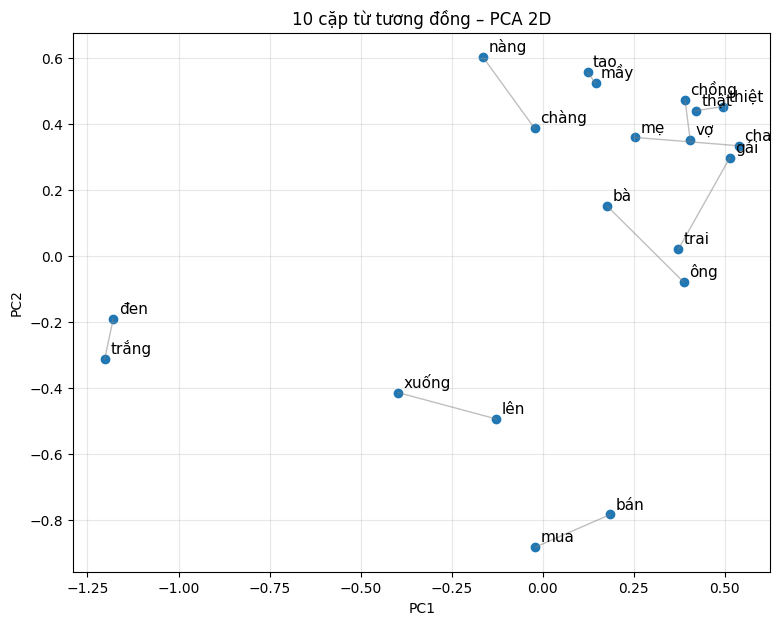

In [55]:
FIG_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 7))
for a, b in pairs:
    (xa, ya), (xb, yb) = pos2[a], pos2[b]
    ax.plot([xa, xb], [ya, yb], color="gray", alpha=0.5, linewidth=1)
for w, (x, y) in pos2.items():
    ax.scatter(x, y, color="tab:blue")
    ax.annotate(w, (x, y), textcoords="offset points", xytext=(4, 4), fontsize=11)
ax.set_title("10 cặp từ tương đồng – PCA 2D")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "pca_2d.png", dpi=150, bbox_inches="tight")
plt.show()

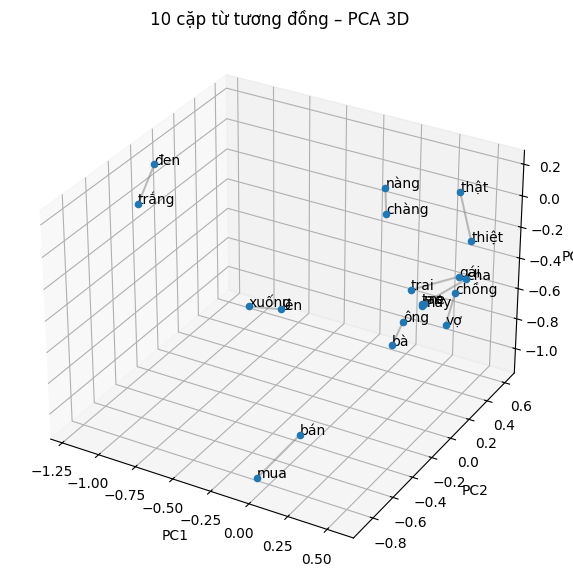

In [56]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for a, b in pairs:
    pa, pb = pos3[a], pos3[b]
    ax.plot([pa[0], pb[0]], [pa[1], pb[1]], [pa[2], pb[2]], color="gray", alpha=0.5)
for w, (x, y, z) in pos3.items():
    ax.scatter(x, y, z, color="tab:blue")
    ax.text(x, y, z, w, fontsize=10)
ax.set_title("10 cặp từ tương đồng – PCA 3D")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
fig.savefig(FIG_DIR / "pca_3d.png", dpi=150, bbox_inches="tight")
plt.show()